# Análise textual do campo objetoCompra nas contratações públicas de São Paulo

**Fonte:** API de Dados Abertos do Compras.gov.br / PNCP  
**Recorte consultado:** Pregão Eletrônico (código 5), unidades de São Paulo, publicações de 1º a 15 de maio de 2025.  
**Coleta registrada:** 30/09/2026; a API informou 1.429 registros.  
**Campo textual analisado:** `objetoCompra`.

## Objetivo

Descrever os temas que aparecem nos textos de `objetoCompra` retornados pela API para o recorte definido. A análise é descritiva e não permite generalizações para outros períodos, modalidades ou estados.

## Pergunta de pesquisa e hipótese

**Pergunta de pesquisa:** quais temas aparecem com maior frequência nas descrições dos objetos de compra no período e na UF analisados?

**Hipótese exploratória:** temas administrativos genéricos — definidos neste notebook como Manutenção e Obras, Limpeza e Higiene e Locação, Terceirização e Apoio Administrativo — concentrariam grande parte dos registros.

A hipótese é avaliada pela frequência de contratações. Frequência de registros e volume financeiro são indicadores diferentes e serão apresentados separadamente.

## 1. Configuração e Instalação de Bibliotecas

In [1]:
%pip install requests pandas matplotlib wordcloud nltk -q

In [2]:
import time
import requests
import pandas as pd
import matplotlib.pyplot as plt

## Fonte dos dados

- **Fonte:** API pública de Dados Abertos do Compras.gov.br
- **Documentação:** https://dadosabertos.compras.gov.br/swagger-ui/index.html
- **Endpoint utilizado:** `/modulo-contratacoes/1_consultarContratacoes_PNCP_14133`
- **Filtro de período (publicação no PNCP):** 2025-05-01 a 2025-05-15 (as datas efetivas coletadas são conferidas na seção 9)
- **UF filtrada:** SP (`unidadeOrgaoUfSigla`; inclui órgãos estaduais e municipais localizados em SP)
- **Modalidade:** código 5 (Pregão Eletrônico)
- **Amostra:** **todas** as contratações retornadas pela API para esse filtro (coleta paginada até `paginasRestantes = 0`; o total é conferido com `totalRegistros`)

In [3]:
import platform
from datetime import date
import nltk

print("Data da coleta:", date.today())
print("Python", platform.python_version(),
      "| pandas", pd.__version__,
      "| matplotlib", __import__("matplotlib").__version__,
      "| nltk", nltk.__version__,
      "| requests", requests.__version__)

Data da coleta: 2026-09-30
Python 3.13.15 | pandas 2.2.3 | matplotlib 3.10.0 | nltk 3.9.1 | requests 2.32.4


## Unidade de análise

Cada linha do DataFrame representa **uma contratação pública** (um processo licitatório) publicada no PNCP, identificada pelo campo `idCompra`. A análise textual é feita sobre o campo `objetoCompra` de cada contratação individual — não há agregação prévia por órgão ou período.

## 2. Configuração da API

In [4]:
BASE_URL = "https://dadosabertos.compras.gov.br"

ENDPOINT_CONTRATACOES = "/modulo-contratacoes/1_consultarContratacoes_PNCP_14133"
url = BASE_URL + ENDPOINT_CONTRATACOES

print(url)


https://dadosabertos.compras.gov.br/modulo-contratacoes/1_consultarContratacoes_PNCP_14133


## 3. Definição de Parâmetros e Chamada Inicial da API

In [5]:
params = {
    "pagina": 1,
    "tamanhoPagina": 10,
    "dataPublicacaoPncpInicial": "2025-05-01",
    "dataPublicacaoPncpFinal": "2025-05-15",
    "codigoModalidade": 5
}

params

{'pagina': 1,
 'tamanhoPagina': 10,
 'dataPublicacaoPncpInicial': '2025-05-01',
 'dataPublicacaoPncpFinal': '2025-05-15',
 'codigoModalidade': 5}

In [6]:
resposta = requests.get(
    url,
    params=params,
    timeout=60
)

print("Status HTTP:", resposta.status_code)
print("URL consultada:", resposta.url)

Status HTTP: 200
URL consultada: https://dadosabertos.compras.gov.br/modulo-contratacoes/1_consultarContratacoes_PNCP_14133?pagina=1&tamanhoPagina=10&dataPublicacaoPncpInicial=2025-05-01&dataPublicacaoPncpFinal=2025-05-15&codigoModalidade=5


In [7]:
dados = resposta.json()

## 4. Função Auxiliar para Extração de Registros

In [8]:
def extrair_registros(json_resposta):
    if isinstance(json_resposta, list):
        return json_resposta

    if not isinstance(json_resposta, dict):
        return []

    for chave in ["resultado", "resultados", "data", "content"]:
        if chave in json_resposta and isinstance(json_resposta[chave], list):
            return json_resposta[chave]

    return []


registros = extrair_registros(dados)

print("Quantidade de registros encontrados:", len(registros))

Quantidade de registros encontrados: 10


## 5. Processamento e Visualização Inicial dos Dados

In [9]:
df = pd.json_normalize(registros)

print("Dimensão:", df.shape)

df.head()

Dimensão: (10, 52)


,idCompra,numeroControlePNCP,anoCompraPncp,sequencialCompraPncp,orgaoEntidadeCnpj,orgaoSubrogadoCnpj,codigoOrgao,orgaoEntidadeRazaoSocial,orgaoSubrogadoRazaoSocial,orgaoEntidadeEsferaId,...,tipoInstrumentoConvocatorioNome,modoDisputaNomePncp,valorTotalEstimado,valorTotalHomologado,dataInclusaoPncp,dataAtualizacaoPncp,dataPublicacaoPncp,dataAberturaPropostaPncp,dataEncerramentoPropostaPncp,contratacaoExcluida
0,92648305900402025,03643856000173-1-000032/2025,2025,32,03643856000173,None,97067,SERVICO SOCIAL DO COMERCIO - ADMINISTRACAO REG...,None,N,...,Edital,Aberto,179474.46,134994.42,2025-05-02T07:15:29,2025-05-02T07:15:29,2025-05-02T07:15:29,2025-05-02T08:00:00,2025-05-16T09:00:00,False
1,51018005900032025,29979036000140-1-000100/2025,2025,100,29979036000140,None,26661,INSTITUTO NACIONAL DO SEGURO SOCIAL,None,F,...,Edital,Aberto,0.00,NaN,2025-05-02T07:15:34,2025-05-02T07:15:34,2025-05-02T07:15:34,2025-05-02T09:00:00,2025-05-21T10:00:00,False
2,93008805900012025,19481436000178-1-000006/2025,2025,6,19481436000178,None,72415,AGENCIA ESTADUAL DE RECURSOS HIDRICOS - AGERH,None,E,...,Edital,Aberto,10131.09,NaN,2025-05-02T07:15:38,2025-05-22T08:55:28,2025-05-02T07:15:38,2025-05-02T08:00:00,2025-05-21T10:00:00,False
3,92670305900802025,26981455000129-1-000078/2025,2025,78,26981455000129,None,23517,AGENCIA MUNICIPAL DE REGULACAO DE SERVICOS DEL...,None,M,...,Edital,Aberto,1885845.73,864056.09,2025-05-02T07:15:42,2025-05-02T07:15:42,2025-05-02T07:15:42,2025-05-02T08:00:00,2025-05-16T09:00:00,False
4,98013905900422025,04034583000122-1-000041/2025,2025,41,04034583000122,None,52383,MUNICIPIO DE RIO BRANCO,None,M,...,Edital,Aberto,79607.20,43476.20,2025-05-02T07:15:46,2025-05-02T07:15:46,2025-05-02T07:15:46,2025-05-05T08:00:00,2025-05-15T10:00:00,False


In [10]:
for coluna in df.columns:
    print(coluna)

idCompra
numeroControlePNCP
anoCompraPncp
sequencialCompraPncp
orgaoEntidadeCnpj
orgaoSubrogadoCnpj
codigoOrgao
orgaoEntidadeRazaoSocial
orgaoSubrogadoRazaoSocial
orgaoEntidadeEsferaId
orgaoSubrogadoEsferaId
orgaoEntidadePoderId
orgaoSubrogadoPoderId
unidadeOrgaoCodigoUnidade
unidadeSubrogadaCodigoUnidade
unidadeOrgaoNomeUnidade
unidadeSubrogadaNomeUnidade
unidadeOrgaoUfSigla
unidadeSubrogadaUfSigla
unidadeOrgaoMunicipioNome
unidadeSubrogadaMunicipioNome
unidadeOrgaoCodigoIbge
unidadeSubrogadaCodigoIbge
numeroCompra
modalidadeIdPncp
codigoModalidade
modalidadeNome
srp
modoDisputaIdPncp
codigoModoDisputa
amparoLegalCodigoPncp
amparoLegalNome
amparoLegalDescricao
informacaoComplementar
processo
objetoCompra
existeResultado
orcamentoSigilosoCodigo
orcamentoSigilosoDescricao
situacaoCompraIdPncp
situacaoCompraNomePncp
tipoInstrumentoConvocatorioCodigoPncp
tipoInstrumentoConvocatorioNome
modoDisputaNomePncp
valorTotalEstimado
valorTotalHomologado
dataInclusaoPncp
dataAtualizacaoPncp
dataPub

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 52 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   idCompra                               10 non-null     object 
 1   numeroControlePNCP                     10 non-null     object 
 2   anoCompraPncp                          10 non-null     int64  
 3   sequencialCompraPncp                   10 non-null     int64  
 4   orgaoEntidadeCnpj                      10 non-null     object 
 5   orgaoSubrogadoCnpj                     0 non-null      object 
 6   codigoOrgao                            10 non-null     int64  
 7   orgaoEntidadeRazaoSocial               10 non-null     object 
 8   orgaoSubrogadoRazaoSocial              0 non-null      object 
 9   orgaoEntidadeEsferaId                  10 non-null     object 
 10  orgaoSubrogadoEsferaId                 0 non-null      object 
 11  orgaoEnti

## 6. Exploração de Colunas e Tipos de Dados

In [12]:
colunas_interesse = [
    "idCompra",
    "numeroCompra",
    "anoCompraPncp",
    "modalidadeNome",
    "modalidadeIdPncp",
    "unidadeOrgaoUfSigla",
    "unidadeOrgaoNomeUnidade",
    "orgaoEntidadeRazaoSocial",
    "objetoCompra",
    "valorTotalEstimado",
    "valorTotalHomologado",
    "dataPublicacaoPncp",
    "srp"
]

colunas_existentes = [c for c in colunas_interesse if c in df.columns]

print("Colunas encontradas:")
print(colunas_existentes)

df[colunas_existentes].head() if colunas_existentes else df.head()

Colunas encontradas:
['idCompra', 'numeroCompra', 'anoCompraPncp', 'modalidadeNome', 'modalidadeIdPncp', 'unidadeOrgaoUfSigla', 'unidadeOrgaoNomeUnidade', 'orgaoEntidadeRazaoSocial', 'objetoCompra', 'valorTotalEstimado', 'valorTotalHomologado', 'dataPublicacaoPncp', 'srp']


,idCompra,numeroCompra,anoCompraPncp,modalidadeNome,modalidadeIdPncp,unidadeOrgaoUfSigla,unidadeOrgaoNomeUnidade,orgaoEntidadeRazaoSocial,objetoCompra,valorTotalEstimado,valorTotalHomologado,dataPublicacaoPncp,srp
0,92648305900402025,90040,2025,Pregão - Eletrônico,6,MG,SERVICO SOCIAL DO COMERCIO - SESC AR/MG,SERVICO SOCIAL DO COMERCIO - ADMINISTRACAO REG...,Contratação de empresa especializada para serv...,179474.46,134994.42,2025-05-02T07:15:29,False
1,51018005900032025,90003,2025,Pregão - Eletrônico,6,MG,SUPERINTENDENCIA REGIONAL SUDESTE II,INSTITUTO NACIONAL DO SEGURO SOCIAL,Contratação de serviços terceirizados nas área...,0.00,NaN,2025-05-02T07:15:34,False
2,93008805900012025,90001,2025,Pregão - Eletrônico,6,ES,EES - AGENCIA ESTADUAL DE RECURSOS HIDRICOS,AGENCIA ESTADUAL DE RECURSOS HIDRICOS - AGERH,"Contratação de Serviço de Copeiragem, Conserva...",10131.09,NaN,2025-05-02T07:15:38,False
3,92670305900802025,90080,2025,Pregão - Eletrônico,6,AL,"AG. DE LICIT., CONT. E CONV. DE MACEIO",AGENCIA MUNICIPAL DE REGULACAO DE SERVICOS DEL...,Registro preços fornecimento utensílios e prod...,1885845.73,864056.09,2025-05-02T07:15:42,True
4,98013905900422025,90042,2025,Pregão - Eletrônico,6,AC,CAC-PREFEITURA MUNICIPAL DE RIO BRANCO,MUNICIPIO DE RIO BRANCO,Aquisição de material de consumo de água miner...,79607.20,43476.20,2025-05-02T07:15:46,True


## 7. Coleta de Dados Específicos (Filtrando por UF)

In [13]:
params_sp = {
    "pagina": 1,
    "tamanhoPagina": 20,
    "dataPublicacaoPncpInicial": "2025-05-01",
    "dataPublicacaoPncpFinal": "2025-05-15",
    "codigoModalidade": 5,
    "unidadeOrgaoUfSigla": "SP"
}

resposta_sp = requests.get(
    url,
    params=params_sp,
    timeout=60
)

print("Status HTTP:", resposta_sp.status_code)

resposta_sp.raise_for_status()

dados_sp = resposta_sp.json()
registros_sp = extrair_registros(dados_sp)
df_sp = pd.json_normalize(registros_sp)

print("Dimensão:", df_sp.shape)

df_sp.head()

Status HTTP: 200
Dimensão: (20, 52)


,idCompra,numeroControlePNCP,anoCompraPncp,sequencialCompraPncp,orgaoEntidadeCnpj,orgaoSubrogadoCnpj,codigoOrgao,orgaoEntidadeRazaoSocial,orgaoSubrogadoRazaoSocial,orgaoEntidadeEsferaId,...,tipoInstrumentoConvocatorioNome,modoDisputaNomePncp,valorTotalEstimado,valorTotalHomologado,dataInclusaoPncp,dataAtualizacaoPncp,dataPublicacaoPncp,dataAberturaPropostaPncp,dataEncerramentoPropostaPncp,contratacaoExcluida
0,92967905900012025,48198725000162-1-000052/2025,2025,52,48198725000162,None,83589,CAMARA MUNICIPAL DE MOGI GUACU,None,M,...,Edital,Aberto,293237.06,288069.0,2025-05-02T07:16:01,2025-05-02T07:16:01,2025-05-02T07:16:01,2025-05-02T08:00:00,2025-05-16T08:30:00,False
1,09013305900682025,46374500000194-1-003439/2025,2025,3439,46374500000194,None,34952,SECRETARIA DE ESTADO DA SAUDE,None,E,...,Edital,Aberto,91698.92,7525.4,2025-05-02T07:16:21,2025-05-02T07:16:21,2025-05-02T07:16:21,2025-05-02T08:00:00,2025-05-16T09:35:00,False
2,18015805900142025,46377800000127-1-001783/2025,2025,1783,46377800000127,None,35311,SAO PAULO SECRETARIA DA SEGURANCA PUBLICA,None,E,...,Edital,Aberto,52245.06,44000.0,2025-05-02T07:16:35,2025-05-02T07:16:35,2025-05-02T07:16:35,2025-05-02T08:00:00,2025-05-21T09:00:00,False
3,53210105907532025,60747318000162-1-000718/2025,2025,718,60747318000162,None,84184,INSTITUTO DE ASSISTENCIA MEDICA AO SERVIDOR PU...,None,E,...,Edital,Aberto-Fechado,385875.75,174300.0,2025-05-02T07:16:43,2025-05-02T07:16:43,2025-05-02T07:16:43,2025-05-05T08:00:00,2025-05-28T09:00:00,False
4,53210105907542025,60747318000162-1-000719/2025,2025,719,60747318000162,None,84184,INSTITUTO DE ASSISTENCIA MEDICA AO SERVIDOR PU...,None,E,...,Edital,Aberto-Fechado,577107.45,275745.0,2025-05-02T07:17:01,2025-05-02T07:17:01,2025-05-02T07:17:01,2025-05-05T08:00:00,2025-05-29T09:00:00,False


## 8. Coleta paginada de todos os registros

A função percorre as páginas até a API informar que não restam páginas. Assim, o conjunto não fica limitado às primeiras páginas nem a uma amostra arbitrária. Nesta coleta, a API informou 1.429 registros para os filtros definidos; foram recebidos 1.429 e removidas zero duplicatas por `idCompra`.

A consulta usa publicações entre 01/05/2025 e 15/05/2025, Pregão Eletrônico (código 5) e unidades de SP. Nesta resposta da API, as datas observadas nos registros vão de 02/05/2025 a 14/05/2025.

In [14]:
def coletar_todas_paginas(endpoint, parametros, pausa=0.3):
    """Coleta todas as páginas da consulta e devolve (DataFrame, metadados da última resposta)."""
    todos, pagina, meta = [], 1, {}

    while True:
        resposta = requests.get(
            BASE_URL + endpoint,
            params={**parametros, "pagina": pagina},
            timeout=60
        )
        resposta.raise_for_status()

        json_resposta = resposta.json()
        registros = extrair_registros(json_resposta)
        meta = {k: v for k, v in json_resposta.items() if not isinstance(v, list)}

        todos.extend(registros)
        print(f"Página {pagina}/{meta.get('totalPaginas', '?')}: {len(registros)} registros")

        if not registros or meta.get("paginasRestantes", 0) == 0:
            break

        pagina += 1
        time.sleep(pausa)   # evita sobrecarregar a API

    return pd.json_normalize(todos), meta

## 9. Coleta de Dados em Lotes

In [15]:
params_coleta = {
    "tamanhoPagina": 100,
    "dataPublicacaoPncpInicial": "2025-05-01",
    "dataPublicacaoPncpFinal": "2025-05-15",
    "codigoModalidade": 5,
    "unidadeOrgaoUfSigla": "SP"
}

df_coleta, meta = coletar_todas_paginas(ENDPOINT_CONTRATACOES, params_coleta)

total_api = meta.get("totalRegistros")
print("\nColetado:", len(df_coleta), "| total informado pela API:", total_api)
if total_api is not None and len(df_coleta) != total_api:
    print("ATENÇÃO: o total coletado difere do total informado pela API.")

# remove duplicidades por idCompra (esperado: 0)
antes = len(df_coleta)
df_coleta = df_coleta.drop_duplicates(subset="idCompra").reset_index(drop=True)
print("Duplicados removidos:", antes - len(df_coleta))

datas = pd.to_datetime(df_coleta["dataPublicacaoPncp"], errors="coerce")
print("Publicações de", datas.min(), "até", datas.max())

df_coleta.to_csv("amostra.csv", index=False)   # instantâneo dos dados (a API muda com o tempo)
print("Dimensão final:", df_coleta.shape)
df_coleta.head()

Página 1/15: 100 registros
Página 2/15: 100 registros
Página 3/15: 100 registros
Página 4/15: 100 registros
Página 5/15: 100 registros
Página 6/15: 100 registros
Página 7/15: 100 registros
Página 8/15: 100 registros
Página 9/15: 100 registros
Página 10/15: 100 registros
Página 11/15: 100 registros
Página 12/15: 100 registros
Página 13/15: 100 registros
Página 14/15: 100 registros
Página 15/15: 29 registros

Coletado: 1429 | total informado pela API: 1429
Duplicados removidos: 0
Publicações de 2025-05-02 07:16:01 até 2025-05-14 07:37:20
Dimensão final: (1429, 52)


,idCompra,numeroControlePNCP,anoCompraPncp,sequencialCompraPncp,orgaoEntidadeCnpj,orgaoSubrogadoCnpj,codigoOrgao,orgaoEntidadeRazaoSocial,orgaoSubrogadoRazaoSocial,orgaoEntidadeEsferaId,...,tipoInstrumentoConvocatorioNome,modoDisputaNomePncp,valorTotalEstimado,valorTotalHomologado,dataInclusaoPncp,dataAtualizacaoPncp,dataPublicacaoPncp,dataAberturaPropostaPncp,dataEncerramentoPropostaPncp,contratacaoExcluida
0,92967905900012025,48198725000162-1-000052/2025,2025,52,48198725000162,None,83589,CAMARA MUNICIPAL DE MOGI GUACU,None,M,...,Edital,Aberto,293237.06,288069.0,2025-05-02T07:16:01,2025-05-02T07:16:01,2025-05-02T07:16:01,2025-05-02T08:00:00,2025-05-16T08:30:00,False
1,09013305900682025,46374500000194-1-003439/2025,2025,3439,46374500000194,None,34952,SECRETARIA DE ESTADO DA SAUDE,None,E,...,Edital,Aberto,91698.92,7525.4,2025-05-02T07:16:21,2025-05-02T07:16:21,2025-05-02T07:16:21,2025-05-02T08:00:00,2025-05-16T09:35:00,False
2,18015805900142025,46377800000127-1-001783/2025,2025,1783,46377800000127,None,35311,SAO PAULO SECRETARIA DA SEGURANCA PUBLICA,None,E,...,Edital,Aberto,52245.06,44000.0,2025-05-02T07:16:35,2025-05-02T07:16:35,2025-05-02T07:16:35,2025-05-02T08:00:00,2025-05-21T09:00:00,False
3,53210105907532025,60747318000162-1-000718/2025,2025,718,60747318000162,None,84184,INSTITUTO DE ASSISTENCIA MEDICA AO SERVIDOR PU...,None,E,...,Edital,Aberto-Fechado,385875.75,174300.0,2025-05-02T07:16:43,2025-05-02T07:16:43,2025-05-02T07:16:43,2025-05-05T08:00:00,2025-05-28T09:00:00,False
4,53210105907542025,60747318000162-1-000719/2025,2025,719,60747318000162,None,84184,INSTITUTO DE ASSISTENCIA MEDICA AO SERVIDOR PU...,None,E,...,Edital,Aberto-Fechado,577107.45,275745.0,2025-05-02T07:17:01,2025-05-02T07:17:01,2025-05-02T07:17:01,2025-05-05T08:00:00,2025-05-29T09:00:00,False


## 10. Análise Preliminar dos Dados Coletados

In [16]:
print("Linhas duplicadas completas:", df_coleta.duplicated().sum())

if "idCompra" in df_coleta.columns:
    print("IDs de compra duplicados:", df_coleta["idCompra"].duplicated().sum())

Linhas duplicadas completas: 0
IDs de compra duplicados: 0


In [17]:
percentual_ausentes = (
    df_coleta.isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

percentual_ausentes.head(15)

,0
orgaoSubrogadoPoderId,99.790063
orgaoSubrogadoEsferaId,99.790063
orgaoSubrogadoRazaoSocial,99.790063
orgaoSubrogadoCnpj,99.790063
unidadeSubrogadaNomeUnidade,99.790063
unidadeSubrogadaUfSigla,99.790063
unidadeSubrogadaCodigoUnidade,99.790063
unidadeSubrogadaMunicipioNome,99.790063
unidadeSubrogadaCodigoIbge,99.790063
valorTotalHomologado,14.695591


In [18]:
colunas_numericas = df_coleta.select_dtypes(include="number").columns.tolist()

print(colunas_numericas)

if colunas_numericas:
    display(df_coleta[colunas_numericas].describe().T)

['anoCompraPncp', 'sequencialCompraPncp', 'codigoOrgao', 'unidadeOrgaoCodigoIbge', 'unidadeSubrogadaCodigoIbge', 'modalidadeIdPncp', 'codigoModalidade', 'modoDisputaIdPncp', 'codigoModoDisputa', 'amparoLegalCodigoPncp', 'orcamentoSigilosoCodigo', 'situacaoCompraIdPncp', 'tipoInstrumentoConvocatorioCodigoPncp', 'valorTotalEstimado', 'valorTotalHomologado']


,count,mean,std,min,25%,50%,75%,max
anoCompraPncp,1429.0,2.024992e+03,8.742874e-02,2.024000e+03,2025.0,2025.0,2025.0,2.025000e+03
sequencialCompraPncp,1429.0,1.626206e+03,1.643602e+03,1.000000e+00,212.0,973.0,3499.0,1.149100e+04
codigoOrgao,1429.0,5.176602e+04,2.249023e+04,9.300000e+01,34952.0,37459.0,82964.0,9.749700e+04
unidadeOrgaoCodigoIbge,1429.0,3.539267e+06,1.664798e+04,3.501400e+06,3529005.0,3550308.0,3550308.0,3.556305e+06
unidadeSubrogadaCodigoIbge,3.0,3.535040e+06,2.644553e+04,3.504503e+06,3527405.5,3550308.0,3550308.0,3.550308e+06
modalidadeIdPncp,1429.0,6.001400e+00,3.739786e-02,6.000000e+00,6.0,6.0,6.0,7.000000e+00
codigoModalidade,1429.0,5.000000e+00,0.000000e+00,5.000000e+00,5.0,5.0,5.0,5.000000e+00
modoDisputaIdPncp,1429.0,1.668300e+00,9.492640e-01,1.000000e+00,1.0,1.0,3.0,6.000000e+00
codigoModoDisputa,1429.0,1.668300e+00,9.492640e-01,1.000000e+00,1.0,1.0,3.0,6.000000e+00
amparoLegalCodigoPncp,1429.0,1.000000e+00,0.000000e+00,1.000000e+00,1.0,1.0,1.0,1.000000e+00


### Tratamento de valores ausentes

As colunas `orgaoSubrogado*` e `unidadeSubrogada*` estão 100% ausentes neste recorte — isso é esperado, pois só existem quando há sub-rogação de competência entre órgãos, o que não ocorreu nas contratações coletadas. Elas não serão usadas na análise e são descartadas.

O campo `valorTotalHomologado` tem ausências (percentual na célula acima): indicam contratações cujo resultado ainda não foi homologado no momento da coleta, não um erro de dado. Como a análise textual usa apenas `objetoCompra` (sem ausências), essa lacuna não a afeta; a coluna é mantida sem imputação.

In [19]:
colunas_100pct_ausentes = [
    "orgaoSubrogadoCnpj", "orgaoSubrogadoRazaoSocial", "orgaoSubrogadoEsferaId", "orgaoSubrogadoPoderId",
    "unidadeSubrogadaCodigoUnidade", "unidadeSubrogadaNomeUnidade", "unidadeSubrogadaUfSigla",
    "unidadeSubrogadaMunicipioNome", "unidadeSubrogadaCodigoIbge"
]

df_coleta = df_coleta.drop(columns=[c for c in colunas_100pct_ausentes if c in df_coleta.columns])

print("Registros sem objetoCompra:", df_coleta['objetoCompra'].isna().sum())
print("Dimensão após remover colunas 100% ausentes:", df_coleta.shape)


Registros sem objetoCompra: 0
Dimensão após remover colunas 100% ausentes: (1429, 43)


### Conversão de tipos e investigação de valores extremos

`valorTotalEstimado` já é lido como numérico pelo pandas. Já `dataPublicacaoPncp` chega como texto (ex.: `2025-05-02T07:15:29`) e precisa ser convertida para `datetime`.

A estatística descritiva (célula anterior) indica assimetria forte em `valorTotalEstimado` (média muito acima da mediana). Isso é investigado abaixo com a regra do intervalo interquartil (IQR): limite superior = Q3 + 1,5 · (Q3 − Q1).

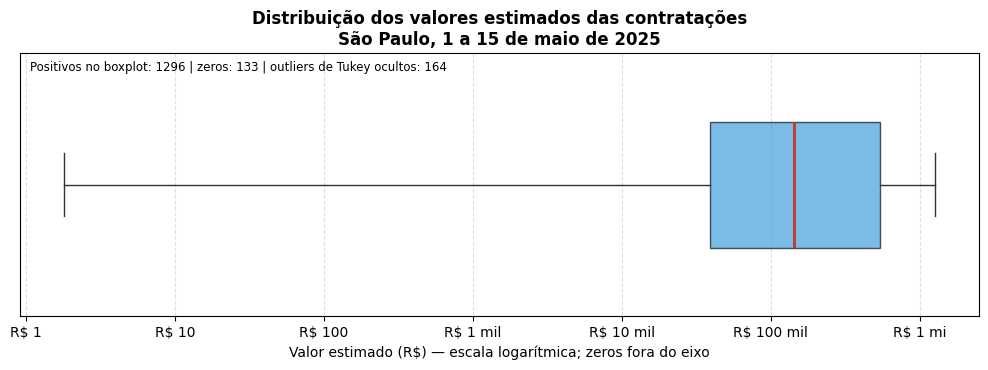

Q1: R$ 39,192.55 | mediana: R$ 144,229.92 | Q3: R$ 541,166.41
Limites de Tukey: R$ -713,768.24 a R$ 1,294,127.20
Valores dentro dos whiskers: 1132 | outliers: 164
Os marcadores dos outliers foram ocultados apenas no desenho. Todos os valores positivos continuam incluídos nos cálculos.
Valores nulos: 0 | zeros: 133 | negativos: 0


In [35]:
import matplotlib.ticker as mticker
import pandas as pd
import matplotlib.pyplot as plt

# O eixo logarítmico não representa zero nem valores negativos.
valores = pd.to_numeric(df_coleta["valorTotalEstimado"], errors="coerce")
valores_validos = valores.dropna()
valores_positivos = valores_validos[valores_validos > 0]

quantidade_zero = int((valores_validos == 0).sum())
quantidade_negativos = int((valores_validos < 0).sum())

if valores_positivos.empty:
    print("Não há valores positivos para representar em escala logarítmica.")
else:
    # A regra de Tukey é calculada sobre todos os valores positivos.
    q1 = valores_positivos.quantile(0.25)
    mediana = valores_positivos.median()
    q3 = valores_positivos.quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    mascara_outliers = (
        (valores_positivos < limite_inferior)
        | (valores_positivos > limite_superior)
    )
    quantidade_outliers = int(mascara_outliers.sum())
    quantidade_dentro_whiskers = len(valores_positivos) - quantidade_outliers

    fig, ax = plt.subplots(figsize=(10, 3.8))

    ax.boxplot(
        valores_positivos,
        vert=False,
        widths=0.48,
        patch_artist=True,
        showfliers=False,  # Oculta os marcadores; não remove valores dos cálculos.
        boxprops=dict(facecolor="#3498db", alpha=0.65),
        medianprops=dict(color="#c0392b", linewidth=2),
        whiskerprops=dict(color="#333333"),
        capprops=dict(color="#333333")
    )

    ax.set_xscale("log")
    ax.set_yticks([])
    ax.set_title(
        "Distribuição dos valores estimados das contratações\n"
        "São Paulo, 1 a 15 de maio de 2025",
        fontsize=12,
        weight="bold"
    )
    ax.set_xlabel(
        "Valor estimado (R$) — escala logarítmica; "
        "zeros fora do eixo"
    )

    def formatar_reais(x, _):
        if x >= 1_000_000_000:
            return f"R$ {x / 1_000_000_000:g} bi"
        if x >= 1_000_000:
            return f"R$ {x / 1_000_000:g} mi"
        if x >= 1_000:
            return f"R$ {x / 1_000:g} mil"
        return f"R$ {x:g}"

    ax.xaxis.set_major_locator(mticker.LogLocator(base=10))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(formatar_reais))
    ax.xaxis.set_minor_locator(mticker.NullLocator())
    ax.grid(axis="x", which="major", linestyle="--", alpha=0.4)

    ax.text(
        0.01, 0.97,
        f"Positivos no boxplot: {len(valores_positivos)} | "
        f"zeros: {quantidade_zero} | "
        f"outliers de Tukey ocultos: {quantidade_outliers}",
        transform=ax.transAxes,
        va="top",
        fontsize=8.5
    )

    plt.tight_layout()
    plt.show()

    print(
        f"Q1: R$ {q1:,.2f} | mediana: R$ {mediana:,.2f} | "
        f"Q3: R$ {q3:,.2f}"
    )
    print(
        f"Limites de Tukey: R$ {limite_inferior:,.2f} a "
        f"R$ {limite_superior:,.2f}"
    )
    print(
        f"Valores dentro dos whiskers: {quantidade_dentro_whiskers} | "
        f"outliers: {quantidade_outliers}"
    )
    print(
        "Os marcadores dos outliers foram ocultados apenas no desenho. "
        "Todos os valores positivos continuam incluídos nos cálculos."
    )
    print(
        f"Valores nulos: {valores.isna().sum()} | "
        f"zeros: {quantidade_zero} | negativos: {quantidade_negativos}"
    )


## 11. Configuração e Pré-processamento de Texto (NLTK)

In [21]:
%pip install nltk -q

import nltk
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import re
from collections import Counter

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


## 12. Análise de Frequência de Palavras

In [22]:
stopwords_pt = set(stopwords.words('portuguese'))

def limpar_e_tokenizar(texto):
    texto = str(texto).lower()
    texto = re.sub(r'[^a-zà-ú\s]', ' ', texto)
    tokens = word_tokenize(texto, language='portuguese')
    tokens = [t for t in tokens if t not in stopwords_pt and len(t) > 2]
    return tokens

df_coleta['tokens'] = df_coleta['objetoCompra'].apply(limpar_e_tokenizar)

In [23]:
todas_palavras = [palavra for tokens in df_coleta['tokens'] for palavra in tokens]

contador = Counter(todas_palavras)
top_30 = contador.most_common(30)

df_freq = pd.DataFrame(top_30, columns=['palavra', 'frequencia'])
df_freq

,palavra,frequencia
0,aquisição,800
1,registro,295
2,preços,283
3,contratação,239
4,serviços,198
5,fornecimento,167
6,medicamentos,150
7,materiais,143
8,prestação,130
9,empresa,124


### Pré-processamento e Remoção de Stopwords

In [24]:
import pandas as pd
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords', quiet=True)

# Stopwords padrão + termos genéricos/jurídico-administrativos recorrentes em licitações
STOPWORDS_EXTRA = {
    "aquisição", "contratação", "registro", "preços", "serviços", "serviço",
    "prestação", "empresa", "especializada", "atender", "atendimento",
    "futura", "eventual", "fornecimento", "material", "materiais", "objeto",
    "conforme", "exclusiva", "período", "condições", "especificações",
    "estabelecidas", "exigências", "tipo", "edital", "anexo", "anexos",
    "consumo", "outros", "necessidades", "quantidades", "demandas", "devidamente",
    "através", "destinados", "unidades", "única", "entrega",
}
stopwords_custom = set(stopwords.words('portuguese')).union(STOPWORDS_EXTRA)

def limpar_tokens(tokens):
    if isinstance(tokens, list):
        return [t.lower() for t in tokens if t.lower() not in stopwords_custom and t.isalpha()]
    return []

# Aplica a limpeza nos tokens existentes
df_coleta['tokens_limpos'] = df_coleta['tokens'].apply(limpar_tokens)
print(f"{len(STOPWORDS_EXTRA)} termos na lista customizada de stopwords")
df_coleta[['objetoCompra', 'tokens_limpos']].head()

39 termos na lista customizada de stopwords


,objetoCompra,tokens_limpos
0,Aquisição de microcomputadores para a Câmara M...,"[microcomputadores, câmara, municipal, mogi, g..."
1,Insumos Judicial Exclusiva,"[insumos, judicial]"
2,Serviço de manutenção e reparos da sede da 4ª ...,"[manutenção, reparos, sede, companhia, trigési..."
3,Contratação de prestação de serviços de saúde ...,"[saúde, atenção, domiciliar, home, care, favor..."
4,Contratação de prestação de serviços de saúde ...,"[saúde, atenção, domiciliar, home, care, favor..."


### Análise de N-Gramas (Termos Frequentes e Bigramas)

In [25]:
from collections import Counter
from nltk.util import ngrams

# 1. Contagem de Palavras Frequentes
todas_palavras = [palavra for sublist in df_coleta['tokens_limpos'] for palavra in sublist]
freq_palavras = Counter(todas_palavras)
df_top_palavras = pd.DataFrame(freq_palavras.most_common(15), columns=['termo', 'frequencia'])

# 2. Contagem de Bigramas (Pares de Palavras)
bigramas = [bg for sublist in df_coleta['tokens_limpos'] for bg in ngrams(sublist, 2)]
freq_bigramas = Counter(bigramas)
df_top_bigramas = pd.DataFrame([(" ".join(bg), count) for bg, count in freq_bigramas.most_common(15)], columns=['bigrama', 'frequencia'])

print("--- Top 5 Termos ---")
print(df_top_palavras.head())

print("\n--- Top 5 Bigramas ---")
print(df_top_bigramas.head())

--- Top 5 Termos ---
          termo  frequencia
0  medicamentos         150
1    manutenção          90
2      judicial          78
3       sistema          70
4       gêneros          62

--- Top 5 Bigramas ---
                bigrama  frequencia
0  gêneros alimentícios          60
1      termo referência          44
2              mão obra          40
3         ação judicial          37
4  constituição sistema          29


### Categorização Temática Regrada

Cada `objetoCompra` recebe **uma** categoria, pela **primeira** regra que casar (a ordem do dicionário é a prioridade). O texto é normalizado (minúsculas, sem acentos) e as regras são expressões regulares, com `\b` nos termos curtos para não casar dentro de outras palavras (ex.: "ti" em "quantidade"). Registros sem nenhuma correspondência ficam em **Outros**.

In [26]:
import re, unicodedata
from collections import Counter

def normalizar(t):
    t = unicodedata.normalize("NFKD", str(t).lower())
    return "".join(c for c in t if not unicodedata.combining(c))

REGRAS = {   # ordem = prioridade (a primeira que casar vence)
    "Saúde": r"medicament|\bmedic[oa]s?\b|medicina|saude|hospitalar|enfermagem|remedio|insumo|reagente|laborator|home care|odontolog|farmac|"
             r"\d\s?(mg|mcg|ml|ui)\b|comprimido|capsula|injetavel|ampola|frasco|cateter|agulha|seringa|\bsondas?\b|canula|ostomia|"
             r"dialis|angioplast|ventilador mecanico|swab|dosagem|esteriliza|indicador biologico|cirurg|trocater|"
             r"grampeador circular|dieta|formula infantil|amamenta|\bkit cpap|vacina|ambulator|curativo|"
             r"esponjas? hidrofobica|\bvac\b|luva.*(procedimento|cirurgic|latex|nitril)|demandas? judiciais?",
    "Alimentação": r"alimenticio|alimento|merenda|panifica|hortifrut|agua mineral|biscoito|copeiragem|legume|congelad|"
                   r"restaurante|hortalica|carne|frango|leite|\barroz\b|feijao",
    "Tecnologia / TI": r"\bti\b|software|computador|tecnologia da informacao|informatica|impressora|toner|telefon|"
                       r"licenca|microsoft|office",
    "Segurança e Justiça": r"policia|militar|batalhao|delegacia|viatura|municao|colete|penitenciari|"
                           r"vigilancia (armada|patrimonial|eletronica)|vigilante|seguranca patrimonial|"
                           r"calculos judiciais|servicos? juridic",
    "Combustíveis e Veículos": r"diesel|gasolina|etanol|combustivel|\bveiculo|pneu|luz de cauda|sinaleira|automotiv",
    "Material de Escritório e Escolar": r"\bpapel\b|papelaria|sulfite|expediente|escritorio|cartucho|escolar|escolares",
    "Manutenção e Obras": r"manutencao|reforma|\bobras?\b|conservacao|\breparos?\b|instalac|\bpecas\b|predial|asfalt|pavimenta|"
                          r"mangueira|\bcimento\b|carregadeira|engenharia|edificios",
    "Limpeza e Higiene": r"limpeza|higien|descartavel|saneante",
    "Locação, Terceirização e Apoio Administrativo": r"locacao|terceiriz|mao de obra|outsourcing|apoio administrativo",
    "Vestuário e EPI": r"uniforme|\bbotas?\b|vestuario|calcado|oculos de protecao|\bepi\b",
    "Equipamentos e Máquinas": r"paleteira|empilhadeira|maquina|equipamento|detector|visor de inspecao",
    "Agropecuária": r"defensivo|fertilizante|adubo|semente|agricol",
    "Educação e Cultura": r"instrumentos? musica|livro|didatic",
    "Comunicação e Eventos": r"comunicacao|publicidade|evento|jornalis|audiovisua",
}
_REG = {k: re.compile(v) for k, v in REGRAS.items()}

CORES = {
    "Saúde": "#e74c3c", "Alimentação": "#f1c40f", "Tecnologia / TI": "#3498db",
    "Segurança e Justiça": "#34495e", "Combustíveis e Veículos": "#e67e22",
    "Material de Escritório e Escolar": "#9b59b6", "Manutenção e Obras": "#2ecc71",
    "Limpeza e Higiene": "#1abc9c", "Locação, Terceirização e Apoio Administrativo": "#16a085",
    "Vestuário e EPI": "#fd79a8", "Equipamentos e Máquinas": "#8e6e53",
    "Agropecuária": "#a3cb38", "Educação e Cultura": "#0984e3",
    "Comunicação e Eventos": "#b53471", "Outros": "#95a5a6",
}

def categorizar_objeto(texto):
    t = normalizar(texto)
    for categoria, rx in _REG.items():
        if rx.search(t):
            return categoria
    return "Outros"

df_coleta['categoria_tema'] = df_coleta['objetoCompra'].apply(categorizar_objeto)

dist = df_coleta['categoria_tema'].value_counts().to_frame('n')
dist['%'] = (dist['n'] / dist['n'].sum() * 100).round(1)
dist

,n,%
categoria_tema,,
Saúde,523,36.6
Outros,402,28.1
Manutenção e Obras,127,8.9
Alimentação,83,5.8
Tecnologia / TI,54,3.8
Material de Escritório e Escolar,52,3.6
Combustíveis e Veículos,50,3.5
Limpeza e Higiene,42,2.9
Segurança e Justiça,37,2.6


#### Inspeção da categoria "Outros"

"Outros" é uma categoria residual: reúne cada objeto que não correspondeu a nenhuma expressão regular de `REGRAS`, na ordem definida no código. A célula seguinte mostra as palavras mais frequentes nesses objetos e uma amostra determinística de até 40 descrições (`SEED = 42`). Essa amostra serve para ilustrar o conteúdo, não para afirmar que todos os 402 registros são iguais.

Use os exemplos para revisar a cobertura do dicionário. Só altere as regras depois de registrar os termos adicionados e rode novamente a classificação e todas as análises dependentes; os percentuais mudam quando a classificação muda.

In [27]:
SEED = 42
outros = df_coleta[df_coleta['categoria_tema'] == 'Outros']
print(f"'Outros': {len(outros)} de {len(df_coleta)} ({len(outros)/len(df_coleta)*100:.1f}%)\n")

sw = stopwords_custom
palavras = [w for t in outros['objetoCompra'] for w in re.findall(r'[a-zà-ú]{3,}', str(t).lower()) if w not in sw]
print(Counter(palavras).most_common(40), "\n")

for t in outros['objetoCompra'].sample(min(40, len(outros)), random_state=SEED):
    print('-', str(t)[:140])

'Outros': 402 de 1429 (28.1%)

[('sistema', 17), ('kit', 14), ('judicial', 13), ('fio', 11), ('paulo', 10), ('municipal', 9), ('meses', 8), ('anti', 8), ('água', 8), ('coleta', 8), ('alimentação', 7), ('município', 7), ('gás', 7), ('constituição', 7), ('estado', 7), ('tratamento', 7), ('demanda', 7), ('especificados', 7), ('confecção', 7), ('presente', 6), ('cumprimento', 6), ('determinação', 6), ('controle', 6), ('tubo', 6), ('adulto', 6), ('trabalho', 6), ('transporte', 6), ('elétricos', 6), ('itens', 6), ('açúcar', 5), ('subordinadas', 5), ('prazo', 5), ('visando', 5), ('concreto', 5), ('móveis', 5), ('proteção', 5), ('placa', 5), ('comodato', 5), ('solução', 5), ('sob', 5)] 

- Contratação de empresa para fornecimento de vale de transporte para servidores celetistas
- Aq ressucitador manual confeccionado em silicone e policarbonato
- Aquisição de colunas para CG AGILENT
- Registro de preços para aquisição de bloqueador solar e repelente para insetos.
- Registro de preços para possí

#### Como revisar e validar a categorização

**“Outros” é uma categoria residual, não um tema:** o código atribui esse rótulo somente quando nenhuma regra temática corresponde ao objeto após a normalização. Para entender o resíduo, os exemplos da célula anterior podem ser relidos e classificados manualmente como (a) categoria existente cuja regra não reconheceu o termo, (b) tema novo recorrente que merece uma regra própria, ou (c) objeto misto/genérico que permanece em “Outros”. A amostra de 40 é exploratória; como há 402 registros, é possível revisar os 402 se a equipe quiser caracterizar todo o resíduo. Não crie uma categoria nova com base em um único exemplo sem justificar a coerência temática.

**Validação independente do classificador:** a planilha cega gerada abaixo contém uma amostra aleatória de até 100 objetos, sem mostrar a categoria automática aos revisores. Dois revisores podem preencher seus rótulos independentemente; depois, compare a concordância entre eles e, após resolver divergências, compare o rótulo adjudicado com a categoria automática. Esta amostra de revisão não reduz o conjunto principal de 1.429 registros. A validação ainda não foi feita nesta execução, então não há taxa de concordância ou acerto a reportar.

O código atual contém 14 categorias temáticas mais “Outros”. Se o artigo apresentar cinco categorias, documente uma tabela de mapeamento entre essas categorias e as cinco do artigo e recalcule as contagens agregadas; não trate as duas taxonomias como se fossem iguais.

In [ ]:
from pathlib import Path

arquivo_validacao = Path("validacao_manual_cega.csv")
colunas_rotulo = ["rotulo_revisor_1", "rotulo_revisor_2", "categoria_adjudicada"]

if not arquivo_validacao.exists():
    n_validacao = min(100, len(df_coleta))
    planilha = df_coleta.sample(n=n_validacao, random_state=123)[
        ["idCompra", "objetoCompra"]
    ].copy()
    # Os rótulos automáticos não são incluídos na planilha enviada aos revisores.
    for coluna in colunas_rotulo:
        planilha[coluna] = ""
    planilha.to_csv(arquivo_validacao, index=False, encoding="utf-8-sig")
    print(
        f"Planilha cega criada com {n_validacao} registros. "
        "Dois revisores devem preencher seus rótulos sem consultar a categoria automática. "
        "Depois de resolver divergências, preencha categoria_adjudicada e carregue o CSV novamente."
    )
else:
    rotulos = pd.read_csv(arquivo_validacao).fillna("")
    rotulados = rotulos[
        rotulos["rotulo_revisor_1"].astype(str).str.strip().ne("")
        & rotulos["rotulo_revisor_2"].astype(str).str.strip().ne("")
    ].copy()

    if rotulados.empty:
        print("A planilha ainda não tem rótulos dos dois revisores; nenhuma concordância foi calculada.")
    else:
        rotulados["rotulo_revisor_1"] = rotulados["rotulo_revisor_1"].astype(str).str.strip()
        rotulados["rotulo_revisor_2"] = rotulados["rotulo_revisor_2"].astype(str).str.strip()
        concordancia = (
            rotulados["rotulo_revisor_1"] == rotulados["rotulo_revisor_2"]
        ).mean() * 100
        print(
            f"Concordância simples entre revisores: {concordancia:.1f}% "
            f"({len(rotulados)} registros com dois rótulos)."
        )

        adjudicados = rotulos[
            rotulos["categoria_adjudicada"].astype(str).str.strip().ne("")
        ].copy()
        if not adjudicados.empty:
            referencia = df_coleta[["idCompra", "categoria_tema"]].drop_duplicates("idCompra")
            comparacao = adjudicados.merge(referencia, on="idCompra", how="left")
            acerto = (
                comparacao["categoria_adjudicada"].astype(str).str.strip()
                == comparacao["categoria_tema"]
            ).mean() * 100
            print(
                f"Concordância do classificador com os rótulos adjudicados: "
                f"{acerto:.1f}% ({len(comparacao)} registros)."
            )
            display(
                comparacao.loc[
                    comparacao["categoria_adjudicada"].astype(str).str.strip()
                    != comparacao["categoria_tema"],
                    ["idCompra", "objetoCompra", "categoria_tema", "categoria_adjudicada"]
                ]
            )

### Distribuição percentual das categorias temáticas

O gráfico de rosca abaixo mostra de forma direta a participação de cada tema no total de contratações analisadas — a visão mais direta para responder à pergunta de pesquisa.


In [ ]:
contagem_categorias = df_coleta["categoria_tema"].value_counts()

fig, ax = plt.subplots(figsize=(9, 7))
wedges, _, autotexts = ax.pie(
    contagem_categorias,
    labels=None,
    autopct=lambda p: f"{p:.1f}%" if p >= 3 else "",
    startangle=90,
    colors=[CORES.get(c, "#cccccc") for c in contagem_categorias.index],
    pctdistance=0.8,
    wedgeprops={"width": 0.4, "edgecolor": "white"}
)
plt.setp(autotexts, size=9, weight="bold", color="white")
ax.legend(
    wedges,
    [f"{categoria} (n={n})" for categoria, n in contagem_categorias.items()],
    title="Categoria e número de registros",
    loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=9
)
ax.set_title(
    f"Participação das categorias em {len(df_coleta):,} contratações\n"
    "SP | Pregão Eletrônico | publicações consultadas: 01–15/05/2025",
    fontsize=11, weight="bold"
)
fig.text(
    0.02, 0.02,
    "Fonte: API de Dados Abertos do Compras.gov.br. Percentual = participação no número de registros.",
    fontsize=8
)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

### Comparação quantitativa: temas por órgão e por unidade

In [30]:
# Distribuição de temas por órgão (10 órgãos com mais registros)
print("Órgãos distintos na amostra:", df_coleta['orgaoEntidadeRazaoSocial'].nunique())

top_orgaos = df_coleta['orgaoEntidadeRazaoSocial'].value_counts().head(10).index

comparacao_orgao_tema = (
    df_coleta[df_coleta['orgaoEntidadeRazaoSocial'].isin(top_orgaos)]
    .groupby(['orgaoEntidadeRazaoSocial', 'categoria_tema'])
    .size()
    .unstack(fill_value=0)
)
# mesma ordem de categorias (e mesmas cores) do gráfico de rosca
comparacao_orgao_tema = comparacao_orgao_tema[[c for c in CORES if c in comparacao_orgao_tema.columns]]
print("Registros nos 10 maiores órgãos:", int(comparacao_orgao_tema.values.sum()), "de", len(df_coleta))

comparacao_orgao_tema

Órgãos distintos na amostra: 157
Registros nos 10 maiores órgãos: 935 de 1429


categoria_tema,Saúde,Alimentação,Tecnologia / TI,Segurança e Justiça,Combustíveis e Veículos,Material de Escritório e Escolar,Manutenção e Obras,Limpeza e Higiene,"Locação, Terceirização e Apoio Administrativo",Vestuário e EPI,Equipamentos e Máquinas,Agropecuária,Educação e Cultura,Comunicação e Eventos,Outros
orgaoEntidadeRazaoSocial,,,,,,,,,,,,,,,
FUNDO MUNICIPAL DE SAUDE - FMS,47,0,0,0,0,0,0,2,0,0,0,0,0,0,10
HOSPITAL DAS CLINICAS DA FACULDADE DE MEDICINA DA U S P,26,1,0,1,0,1,1,0,0,0,1,0,0,0,14
INSTITUTO DE ASSISTENCIA MEDICA AO SERVIDOR PUBLICO ESTADUAL,57,0,1,0,0,2,2,3,0,0,0,0,0,0,32
MUNICIPIO DE BAURU,4,2,1,0,1,1,3,0,1,0,0,0,0,0,15
SAO PAULO SECRETARIA DA ADMINISTRACAO PENITENCIARIA,4,37,2,2,2,1,2,5,0,0,1,0,0,0,10
SAO PAULO SECRETARIA DA SEGURANCA PUBLICA,10,18,8,23,10,4,13,5,0,2,2,0,0,0,27
SECRETARIA DE ESTADO DA SAUDE,246,2,10,2,2,6,11,5,2,0,3,0,0,1,96
UNIVERSIDADE DE SAO PAULO,8,0,5,0,1,6,15,1,4,0,1,0,2,0,41
UNIVERSIDADE ESTADUAL DE CAMPINAS,12,1,0,0,1,0,2,0,0,0,1,0,1,0,3


In [ ]:
import textwrap

fig, ax = plt.subplots(figsize=(12, 8))
labels_quebrados = [
    "\n".join(textwrap.wrap(nome, width=25))
    for nome in comparacao_orgao_tema.index
]
comparacao_orgao_tema.plot(
    kind="barh", stacked=True, ax=ax,
    color=[CORES[c] for c in comparacao_orgao_tema.columns]
)
ax.set_yticklabels(labels_quebrados, fontsize=8)
registros_top10 = int(comparacao_orgao_tema.values.sum())
ax.set_title(
    f"Categorias nos 10 órgãos com mais registros ({registros_top10} de {len(df_coleta)})\n"
    "SP | Pregão Eletrônico | publicações consultadas: 01–15/05/2025",
    fontsize=11
)
ax.set_xlabel("Número de contratações")
ax.set_ylabel("Órgão comprador")
ax.legend(title="Categoria", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
fig.text(0.02, 0.02, "Fonte: API de Dados Abertos do Compras.gov.br. Análise descritiva; não indica causalidade.", fontsize=8)
plt.subplots_adjust(left=0.28, right=0.72, top=0.88, bottom=0.1)
plt.show()

### Frequência de contratações × volume financeiro

Frequência (nº de contratações) e valor (R$) **não** são equivalentes: uma categoria pode ser frequente e de baixo valor, ou rara e de valor alto. A tabela abaixo apresenta as duas dimensões por categoria.

In [32]:
tabela_valores = (
    df_coleta.groupby('categoria_tema')
    .agg(contratacoes=('idCompra', 'count'),
         soma_estimado=('valorTotalEstimado', 'sum'),
         mediana_estimado=('valorTotalEstimado', 'median'),
         soma_homologado=('valorTotalHomologado', 'sum'))
    .assign(pct_contratacoes=lambda d: d.contratacoes / d.contratacoes.sum() * 100,
            pct_valor_estimado=lambda d: d.soma_estimado / d.soma_estimado.sum() * 100)
    .sort_values('contratacoes', ascending=False)
    .round(1)
)
display(tabela_valores)

# maior contratação: a qual categoria pertence?
maior = df_coleta.loc[df_coleta['valorTotalEstimado'].idxmax()]
print(f"Maior valorTotalEstimado: R$ {maior['valorTotalEstimado']:,.2f} | categoria: {maior['categoria_tema']} | {str(maior['objetoCompra'])[:100]}")

,contratacoes,soma_estimado,mediana_estimado,soma_homologado,pct_contratacoes,pct_valor_estimado
categoria_tema,,,,,,
Saúde,523,820174848.2,81565.0,406354433.5,36.6,42.5
Outros,402,508864493.0,84976.6,400054804.5,28.1,26.4
Manutenção e Obras,127,150807215.6,189000.0,102048275.6,8.9,7.8
Alimentação,83,43347625.8,272710.0,26395543.5,5.8,2.2
Tecnologia / TI,54,48101961.3,165750.7,36392085.0,3.8,2.5
Material de Escritório e Escolar,52,76892654.1,130628.9,44478472.7,3.6,4.0
Combustíveis e Veículos,50,83168708.1,226565.8,55785664.2,3.5,4.3
Limpeza e Higiene,42,30954126.4,75027.6,16467276.3,2.9,1.6
Segurança e Justiça,37,103820156.5,155529.8,81536006.2,2.6,5.4


Maior valorTotalEstimado: R$ 256,866,912.33 | categoria: Outros | Operacionalização do Acordo RED HAT - PRO.00.8387, para fornecimento de produtos e serviços da tecno


### Teste da hipótese

A hipótese considera "temas administrativos genéricos" o grupo **Manutenção e Obras + Limpeza e Higiene + Locação/Terceirização/Apoio Administrativo**.

In [33]:
GRUPO_ADMIN = ["Manutenção e Obras", "Limpeza e Higiene", "Locação, Terceirização e Apoio Administrativo"]
cat = df_coleta['categoria_tema']

pct_admin = cat.isin(GRUPO_ADMIN).mean() * 100
pct_saude = (cat == 'Saúde').mean() * 100
pct_outros = (cat == 'Outros').mean() * 100
maior_cat = cat.value_counts().index[0]

print(f"Total de contratações: {len(df_coleta)}")
print(f"Grupo administrativo genérico: {pct_admin:.1f}%")
print(f"Saúde: {pct_saude:.1f}%")
print(f"Outros (resíduo): {pct_outros:.1f}%")
print(f"Categoria mais frequente: {maior_cat} ({cat.value_counts().iloc[0]} contratações)")
print("Hipótese (admin. genérico concentra a maior parte):", "CONFIRMADA" if pct_admin > 50 else "NÃO CONFIRMADA")

Total de contratações: 1429
Grupo administrativo genérico: 12.9%
Saúde: 36.6%
Outros (resíduo): 28.1%
Categoria mais frequente: Saúde (523 contratações)
Hipótese (admin. genérico concentra a maior parte): NÃO CONFIRMADA


### Visualizações Gráficas (Gráfico de Barras e Nuvem de Palavras)

In [ ]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Barras: frequência de ocorrências dos termos após a limpeza textual.
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(df_top_palavras["termo"][::-1], df_top_palavras["frequencia"][::-1], color="#3498db")
ax.set_title(
    f"15 termos mais frequentes nos objetos (n={len(df_coleta)} registros)\n"
    "SP | Pregão Eletrônico | publicações consultadas: 01–15/05/2025"
)
ax.set_xlabel("Número de ocorrências nos textos limpos de objetoCompra")
ax.set_ylabel("Termo")
fig.text(0.02, 0.02, "Fonte: API de Dados Abertos do Compras.gov.br. Stopwords padrão e lista customizada removidas.", fontsize=8)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

# Nuvem: representação visual das mesmas frequências, sem escala quantitativa nos eixos.
wc = WordCloud(width=800, height=400, background_color="white", max_words=100).generate_from_frequencies(freq_palavras)
fig, ax = plt.subplots(figsize=(10, 5))
ax.imshow(wc, interpolation="bilinear")
ax.axis("off")
ax.set_title(
    f"Nuvem de palavras dos objetos de compra (n={len(df_coleta)} registros)\n"
    "SP | Pregão Eletrônico | publicações consultadas: 01–15/05/2025"
)
fig.text(0.02, 0.02, "Fonte: API de Dados Abertos do Compras.gov.br. Tamanho da palavra representa sua frequência após limpeza.", fontsize=8)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

## Discussão

A coleta paginada retornou **1.429 registros**, o mesmo total informado pela API, sem duplicatas por `idCompra`. Os filtros consultaram publicações de 1º a 15 de maio de 2025, Pregão Eletrônico (código 5) e unidades de São Paulo; na resposta coletada, as datas dos registros vão de 2 a 14 de maio. Trata-se do conjunto retornado para esses filtros na data da coleta, não de uma amostra aleatória de todas as compras públicas.

A categoria mais frequente foi **Saúde**, com 523 registros (36,6%), seguida de **Outros**, com 402 (28,1%), e **Manutenção e Obras**, com 127 (8,9%). A hipótese de que o grupo administrativo definido no notebook (Manutenção e Obras, Limpeza e Higiene e Locação/Terceirização/Apoio Administrativo) concentraria mais da metade dos registros não foi confirmada: o grupo somou 12,9%. Saúde, isoladamente, foi a categoria mais frequente.

**Interpretação de “Outros”.** A categoria contém registros sem correspondência em nenhuma regra; não representa um tema único. Na amostra inspecionada aparecem objetos de saúde, alimentação, tecnologia, transporte e gases. Há exemplos que parecem pertencer a categorias específicas já existentes — como testes hormonais, coffee break e produtos Red Hat —, o que sugere que a lista de termos não cobre todas as descrições. A inspeção é exploratória; não se deve concluir que esses exemplos representem os 402 registros inteiros. As regras precisam de revisão documentada e, se forem alteradas, todos os resultados devem ser recalculados.

**Frequência e valor são medidas diferentes.** Saúde representa 36,6% dos registros e 42,5% do valor estimado; “Outros”, 28,1% dos registros e 26,4% do valor. Segurança e Justiça tem 2,6% dos registros, mas 5,4% do valor estimado. A maior contratação estimada foi de R$ 256.866.912,33 e foi classificada como “Outros”; esse único registro influencia a soma financeira da categoria. O valor total não deve ser interpretado como número de processos.

Após a limpeza textual, os termos mais frequentes foram “medicamentos” (150), “manutenção” (90), “judicial” (78), “sistema” (70) e “gêneros” (62). O bigrama mais frequente foi “gêneros alimentícios” (60). Frequências de palavras descrevem ocorrências nos textos, não quantidade de contratações por tema.

A comparação dos dez órgãos com mais registros cobre 935 dos 1.429 casos (65,4%). As diferenças entre órgãos são descritivas e não demonstram que o tipo de órgão cause determinado padrão de compras.

**Validação da categorização:** não foi concluída nesta execução. O notebook exporta um modelo de rotulagem manual, mas não há rótulos preenchidos; por isso, não há taxa de acerto a reportar.

## Limitações

- **Escopo:** a consulta cobre publicações de 01 a 15/05/2025, Pregão Eletrônico (código 5) e unidades de SP. Os registros retornados nesta coleta têm datas de publicação entre 02 e 14/05/2025. Os resultados não se generalizam automaticamente para outros períodos, modalidades ou estados.
- **API mutável:** os 1.429 registros são o total informado e retornado pela API na coleta registrada em 30/09/2026. A consulta pode mudar com atualizações da fonte. O código salva o conjunto completo em `amostra.csv`; apesar do nome, esse arquivo contém todos os registros retornados pelos filtros, não uma amostra de 60.
- **Classificação por regras:** cada descrição recebe apenas a primeira categoria cujas expressões regulares correspondem ao texto. Descrições podem misturar temas, e erros, abreviações e sinônimos reduzem a cobertura.
- **Categoria residual:** “Outros” reúne 402 registros (28,1%) sem correspondência nas regras. A amostra inspecionada indica lacunas, mas não descreve todos os 402 casos.
- **Validação manual:** nenhum rótulo manual foi preenchido nesta execução. A concordância não foi medida e não há taxa de acerto a reportar.
- **Valores monetários:** 133 registros têm valor estimado igual a zero. O boxplot logarítmico mostra apenas os 1.296 valores positivos; os zeros são informados à parte. Foram identificados 164 valores acima do limite superior de Tukey entre os positivos; eles permanecem nos cálculos e não são automaticamente erros.
- **Associação:** a distribuição por órgão é descritiva e não estabelece causalidade.

## Conclusão

Para o conjunto retornado pela API nos filtros definidos — 1.429 contratações do Estado de São Paulo, na modalidade Pregão Eletrônico, publicadas entre 1º e 15 de maio de 2025 —, os temas mais frequentes foram Saúde (36,6%), “Outros” (28,1%) e Manutenção e Obras (8,9%). A hipótese de que temas administrativos genéricos concentrariam a maioria dos registros não foi confirmada: o grupo definido no notebook correspondeu a 12,9% dos casos.

A participação de “Outros” mostra que as regras atuais não capturam toda a diversidade dos objetos e limita a interpretação temática. A análise financeira também não equivale à frequência: Saúde representa 42,5% do valor estimado, e uma contratação classificada como “Outros” tem o maior valor individual. Esses resultados descrevem somente o recorte consultado; não há validação manual concluída nem base para generalizar a outros períodos ou unidades federativas.

Como próximos passos científicos, recomenda-se revisar as regras com exemplos de “Outros”, rotular uma amostra independente para avaliar a classificação e ampliar o recorte temporal e geográfico. Qualquer revisão do dicionário deve ser seguida da reexecução de todas as contagens, tabelas e figuras.